# Task 3 — Cognitive load and the data-ink ratio

The point of the task is that the chart audience should not have to carry a large legend, extra labels, or extra axes in working memory. Good design removes the load that does not help the message.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

base = Path('data')
car = pd.read_csv(base / 'car_crashes.csv')
car.head()

,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,7.332,5.640,18.048,15.040,784.55,145.08,AL
1,18.1,7.421,4.525,16.290,17.014,1053.48,133.93,AK
2,18.6,6.510,5.208,15.624,17.856,899.47,110.35,AZ
3,22.4,4.032,5.824,21.056,21.280,827.34,142.39,AR
4,12.0,4.200,3.360,10.920,10.680,878.41,165.63,CA


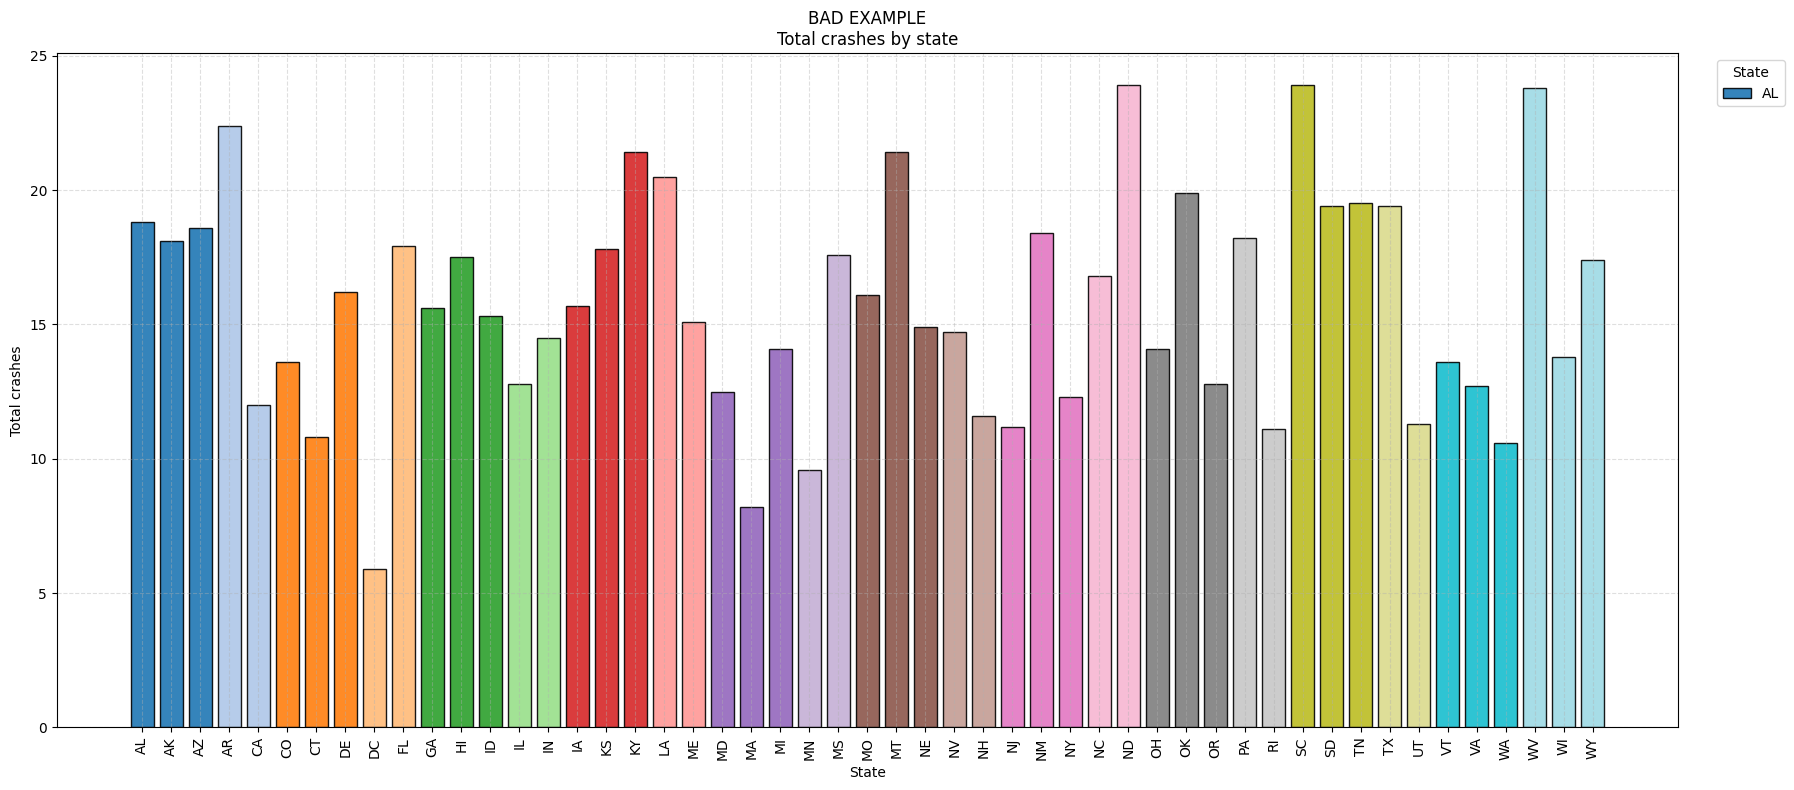

In [2]:
fig, ax = plt.subplots(figsize=(18, 8))
colors = plt.cm.tab20(np.linspace(0, 1, len(car)))
ax.bar(car['abbrev'], car['total'], color=colors, edgecolor='black', alpha=0.9)
ax.set_title('BAD EXAMPLE\nTotal crashes by state', loc='center')
ax.set_xlabel('State')
ax.set_ylabel('Total crashes')
ax.grid(True, axis='both', linestyle='--', alpha=0.4)
ax.legend(car['abbrev'], title='State', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
ax.tick_params(axis='x', rotation=90)
fig.tight_layout()

In [3]:
# Data-ink estimate
# all 51 state bars encode numbers, but the chart adds a legend with 51 entries, a frame, white space, and heavy gridlines. The data-ink ratio is therefore much smaller than 1.0, because most of the ink is decoration rather than encoding.
# A rough estimate would be: 51 bars + 51 labels + 1 x-axis + 1 y-axis = ~104 marks, while the display contains well over 1000 additive marks when the gridlines, legend, and frame are counted. The ratio is therefore low.

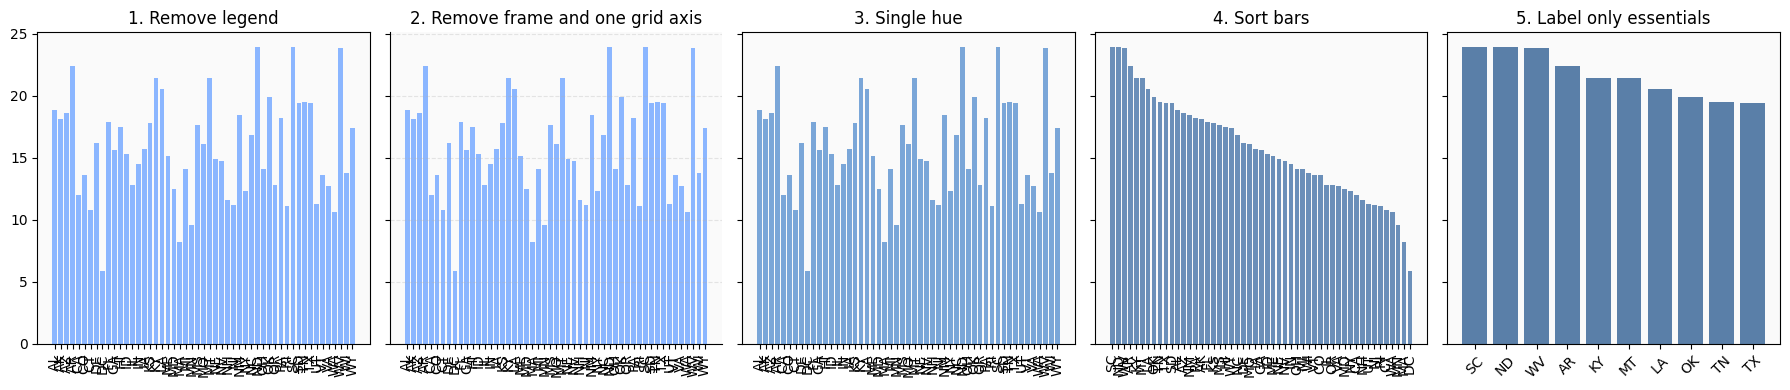

In [4]:
# Five-step declutter
fig, axes = plt.subplots(1, 5, figsize=(18, 4), sharey=True)
car_sorted = car.sort_values('total', ascending=False).reset_index(drop=True)
for ax in axes:
    ax.set_facecolor('#fafafa')
ax = axes[0]
ax.bar(car['abbrev'], car['total'], color='#8bb6ff')
ax.set_title('1. Remove legend')
ax.tick_params(axis='x', rotation=90)
ax = axes[1]
ax.bar(car['abbrev'], car['total'], color='#8bb6ff')
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='x', rotation=90)
ax.set_title('2. Remove frame and one grid axis')
ax = axes[2]
ax.bar(car['abbrev'], car['total'], color='#7aa6d8')
ax.tick_params(axis='x', rotation=90)
ax.set_title('3. Single hue')
ax = axes[3]
ax.bar(car_sorted['abbrev'], car_sorted['total'], color='#6b8fb9')
ax.tick_params(axis='x', rotation=90)
ax.set_title('4. Sort bars')
ax = axes[4]
ax.bar(car_sorted['abbrev'].head(10), car_sorted['total'].head(10), color='#5a7fa8')
ax.tick_params(axis='x', rotation=45)
ax.set_title('5. Label only essentials')
fig.tight_layout()

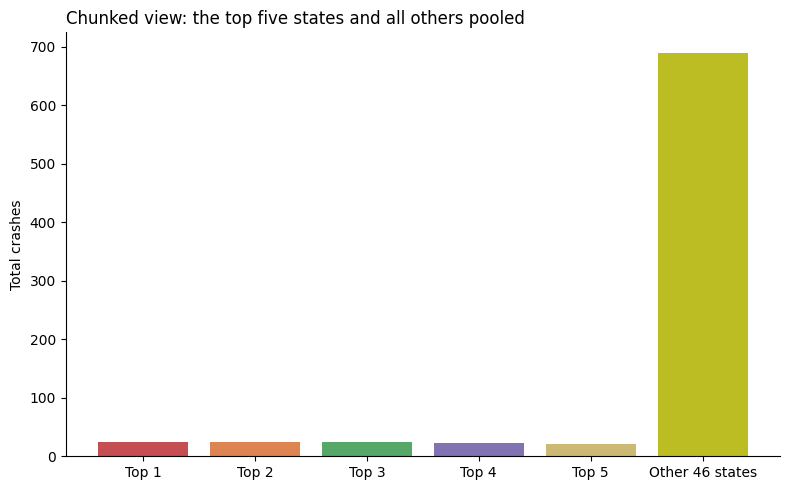

In [5]:
# Chunking under the 4 ± 1 limit
chunk = pd.DataFrame({
    'category': ['Top 1', 'Top 2', 'Top 3', 'Top 4', 'Top 5', 'Other 46 states'],
    'value': [car_sorted.iloc[0]['total'], car_sorted.iloc[1]['total'], car_sorted.iloc[2]['total'], car_sorted.iloc[3]['total'], car_sorted.iloc[4]['total'], car_sorted.iloc[5:]['total'].sum()]
})
fig, ax = plt.subplots(figsize=(8,5))
ax.bar(chunk['category'], chunk['value'], color=['#c44e52','#dd8452','#55a868','#8172b2','#ccb974','#bcbd22'])
ax.set_title('Chunked view: the top five states and all others pooled', loc='left')
ax.set_ylabel('Total crashes')
for side in ('top','right'):
    ax.spines[side].set_visible(False)
fig.tight_layout()

In [6]:
# Stopping rule
# Stop removing ink when the comparison or the key message becomes harder to decode than the saved clutter: if a reader cannot tell the ranking or the difference between categories, the chart has been over-stripped.